# NMOS LVT — Temperature Dependence Summary

Cryogenic characterization of the 28 nm NMOS **LVT** array (board 1, chip 2).
This notebook summarizes how **threshold voltage** ($V_{th}$) and **saturation current** ($I_{sat}$)
evolve from room temperature down to 80 K, across the device-geometry matrix.

**Data source:** full $V_g$ *transfer* sweeps (routine 1, 30 $V_g$ pts $\times$ 10 $V_d$ pts per device).

| Temperature | File(s) |
|---|---|
| 295 K | `..._NMOS_LVT_vgsweep_295K.csv` *(filling in)* |
| 175 K | `..._NMOS_LVT_vgsweep_175K.csv` |
| 80 K  | `..._NMOS_LVT_vgsweep_80K.csv` + `..._part2.csv` |

The notebook auto-detects which temperatures are present, so re-run it as more data lands.

**Geometry matrix:** $W \in \{0.1, 0.2, 0.4\}\,\mu m$ (set by row pair), with gate length
$L$ and finger count $n_f$ varying across the 25 columns.

## 1. Setup and data loading

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = '../data'

def dp(name):
    return os.path.join(DATA_DIR, name)

# Full Vg transfer sweeps (30 Vg x 10 Vd grid) at each temperature.
TEMP_FILES = {
    295: [dp('array_scan_board1_chip2_NMOS_LVT_vgsweep_295K.csv')],
    175: [dp('array_scan_board1_chip2_NMOS_LVT_vgsweep_175K.csv')],
    80:  [dp('array_scan_board1_chip2_NMOS_LVT_vgsweep_80K.csv'),
          dp('array_scan_board1_chip2_NMOS_LVT_vgsweep_80K_part2.csv')],
}

# Low-Vd (0.05 V) fast Vg sweeps for clean subthreshold curves.
FAST_FILES = {
    295: [dp('array_scan_board1_chip2_NMOS_LVT_vgsweep_vdsp0p05_295K.csv')],
    80:  [dp('array_scan_board1_chip2_NMOS_LVT_vgsweep_vdsp0p05_80K.csv')],
}

def load_temperature(files):
    frames = []
    for f in files:
        if os.path.exists(f) and os.path.getsize(f) > 0:
            df = pd.read_csv(f)
            if len(df):
                frames.append(df)
    if not frames:
        return None
    df = pd.concat(frames, ignore_index=True)
    for c in ['w', 'l', 'nf', 'vg', 'vd', 'id']:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    return df


def add_baseline_corrected(df):
    """Add an 'id_corr' column = measured Id minus the per-(device, Vd) leakage
    baseline, defined as Id at Vg=0 for that same device and Vd. This removes the
    leakage flowing through the non-selected (inactive) array devices, which grows
    with Vd. The channel is off at Vg=0 (NMOS Vth ~ 0.3-0.5 V), so Id(Vg=0) is
    essentially pure background."""
    df = df.copy()
    df['_vd_key'] = df['vd'].round(4)
    base = (df[np.isclose(df['vg'], 0.0, atol=1e-3)]
            .groupby(['Row_idx', 'Col_idx', '_vd_key'])['id'].mean()
            .rename('id_base').reset_index())
    df = df.merge(base, on=['Row_idx', 'Col_idx', '_vd_key'], how='left')
    df['id_base'] = df['id_base'].fillna(0.0)
    df['id_corr'] = df['id'] - df['id_base']
    return df.drop(columns='_vd_key')


data = {T: load_temperature(files) for T, files in TEMP_FILES.items()}
data = {T: df for T, df in data.items() if df is not None}
data = {T: add_baseline_corrected(df) for T, df in data.items()}
TEMPS = sorted(data.keys(), reverse=True)

# Low-Vd (0.05 V) fast sweeps, loaded separately for the subthreshold plot.
fast_data = {T: load_temperature(files) for T, files in FAST_FILES.items()}
fast_data = {T: df for T, df in fast_data.items() if df is not None}
fast_data = {T: add_baseline_corrected(df) for T, df in fast_data.items()}

if not TEMPS:
    print('No LVT transfer data found yet.')
for T in TEMPS:
    ndev = data[T].groupby(['Row_idx', 'Col_idx']).ngroups
    has_fast = 'yes (Vd=0.05 V)' if T in fast_data else 'no (use Vd=0.1 V)'
    print(f'{T:>4} K : {len(data[T]):>6} rows, {ndev:>3} devices | fast low-Vd sweep: {has_fast}')

 295 K :  45000 rows, 150 devices | fast low-Vd sweep: yes (Vd=0.05 V)
 175 K :  45000 rows, 150 devices | fast low-Vd sweep: no (use Vd=0.1 V)
  80 K :  45000 rows, 150 devices | fast low-Vd sweep: yes (Vd=0.05 V)


## 2. Metric extraction

For every device we compute:

- **$V_{th}$** — **maximum-transconductance linear-extrapolation** method. At the lowest
  non-zero $V_d$ (linear region) we find the gate voltage of peak $g_m = dI_d/dV_g$, draw
  the tangent there, and take its $V_g$-axis intercept minus $V_d/2$:
  $V_{th} = V_g^{peak} - I_d^{peak}/g_m^{peak} - V_d/2$. This is robust to subthreshold
  leakage (unlike a fixed constant-current level, which fails when the off-current already
  exceeds the criterion — as happens for short-channel devices at 295 K).

- **$I_{sat}$** — drain current at maximum bias ($V_g = 0.9\,$V, $V_d = 0.9\,$V), the on-state /
  saturation drive current. Also reported normalized per unit width ($I_{sat} / (W\,n_f)$) for
  cross-geometry comparison.

All currents used below are **leakage-subtracted** (`id_corr` = $I_d - I_d(V_g{=}0)$ evaluated per device and per $V_d$; see §4b for an illustration).

In [ ]:
def extract_vth(dev_df, vd_lin):
    """Max-transconductance linear-extrapolation Vth at the linear Vd slice.
    Vth = Vg(peak gm) - Id(peak gm)/gm_peak - Vd/2. Robust to subthreshold leakage.
    Uses the leakage-subtracted current (id_corr) when available.
    Returns np.nan if a sane value cannot be found."""
    s = dev_df[np.isclose(dev_df['vd'], vd_lin, atol=1e-3)].sort_values('vg')
    if len(s) < 3:
        return np.nan
    vg = s['vg'].to_numpy(dtype=float)
    col = 'id_corr' if 'id_corr' in s.columns else 'id'
    idd = s[col].to_numpy(dtype=float)
    gm = np.gradient(idd, vg)
    k = int(np.nanargmax(gm))
    if not np.isfinite(gm[k]) or gm[k] <= 0:
        return np.nan
    vth = vg[k] - idd[k] / gm[k] - vd_lin / 2.0
    # Reject nonphysical extrapolations well outside the swept range.
    if vth < vg.min() - 0.2 or vth > vg.max() + 0.2:
        return np.nan
    return vth


def extract_isat(dev_df, vg_max, vd_max):
    """Id at the max-bias corner (on-current / saturation drive), leakage-subtracted."""
    s = dev_df[np.isclose(dev_df['vg'], vg_max, atol=1e-2) &
               np.isclose(dev_df['vd'], vd_max, atol=1e-2)]
    col = 'id_corr' if 'id_corr' in s.columns else 'id'
    return float(s[col].iloc[0]) if len(s) else np.nan


def build_metrics(df):
    """Per-device metrics table for one temperature."""
    vds = np.sort(df['vd'].unique())
    vd_lin = vds[vds > 1e-6][0]          # lowest non-zero Vd (linear region)
    vg_max, vd_max = df['vg'].max(), df['vd'].max()
    recs = []
    for (r, c), g in df.groupby(['Row_idx', 'Col_idx']):
        W, L, nf = g['w'].iloc[0], g['l'].iloc[0], g['nf'].iloc[0]
        isat = extract_isat(g, vg_max, vd_max)
        recs.append({
            'Row_idx': r, 'Col_idx': c,
            'W': W, 'L': L, 'nf': nf,
            'Vth': extract_vth(g, vd_lin),
            'Isat': isat,
            'Isat_per_W': isat / (W * nf) if (W and nf) else np.nan,
        })
    return pd.DataFrame(recs)


metrics = {T: build_metrics(data[T]) for T in TEMPS}
for T in TEMPS:
    m = metrics[T]
    print(f'{T:>4} K : Vth median {m["Vth"].median():.3f} V | '
          f'Isat median {m["Isat"].median()*1e3:.3f} mA | {int(m["Vth"].isna().sum())} Vth NaN')

 295 K : Vth median = 0.311 V,  Isat median = 0.532 mA  (150 devices)
 175 K : Vth median = 0.387 V,  Isat median = 0.577 mA  (150 devices)
  80 K : Vth median = 0.421 V,  Isat median = 0.609 mA  (150 devices)


## 3. Pick representative geometries

We select a small set of geometries present at every available temperature: a fixed
$W = 0.1\,\mu m$, $n_f = 1$ device at several gate lengths $L$. This isolates the
length dependence while keeping width/fingers constant.

In [28]:
def geom_key(row):
    return (round(row['W'], 12), round(row['L'], 12), int(row['nf']))

# Geometries common to all available temperatures
common = None
for T in TEMPS:
    keys = {geom_key(r) for _, r in metrics[T].iterrows()}
    common = keys if common is None else (common & keys)
common = sorted(common) if common else []

# Focus set: W = 0.1 um, nf = 1, sweep L
W_SEL, NF_SEL = 1e-7, 1
L_series = sorted({L for (W, L, nf) in common if np.isclose(W, W_SEL) and nf == NF_SEL})
focus_geoms = [(W_SEL, L, NF_SEL) for L in L_series]

def fmt_geom(W, L, nf):
    return f'W={W*1e9:.0f}nm L={L*1e9:.0f}nm nf={nf}'

print('Length series (W=0.1um, nf=1):')
for g in focus_geoms:
    print('  ', fmt_geom(*g))

Length series (W=0.1um, nf=1):
   W=100nm L=30nm nf=1
   W=100nm L=40nm nf=1
   W=100nm L=60nm nf=1
   W=100nm L=90nm nf=1
   W=100nm L=200nm nf=1
   W=100nm L=500nm nf=1
   W=100nm L=1000nm nf=1


## 4. Transfer curves vs temperature (single geometry)

$I_d$-$V_g$ in the linear region for one geometry, overlaid across temperature.
Cryogenic cooling steepens the subthreshold slope and shifts turn-on.

**$V_d$ used:** where a dedicated fast sweep exists we use $V_d = 0.05\,$V (cleaner
linear/subthreshold region); otherwise we fall back to the lowest transfer-grid step
($V_d = 0.1\,$V). Each curve is labelled with its actual $V_d$.

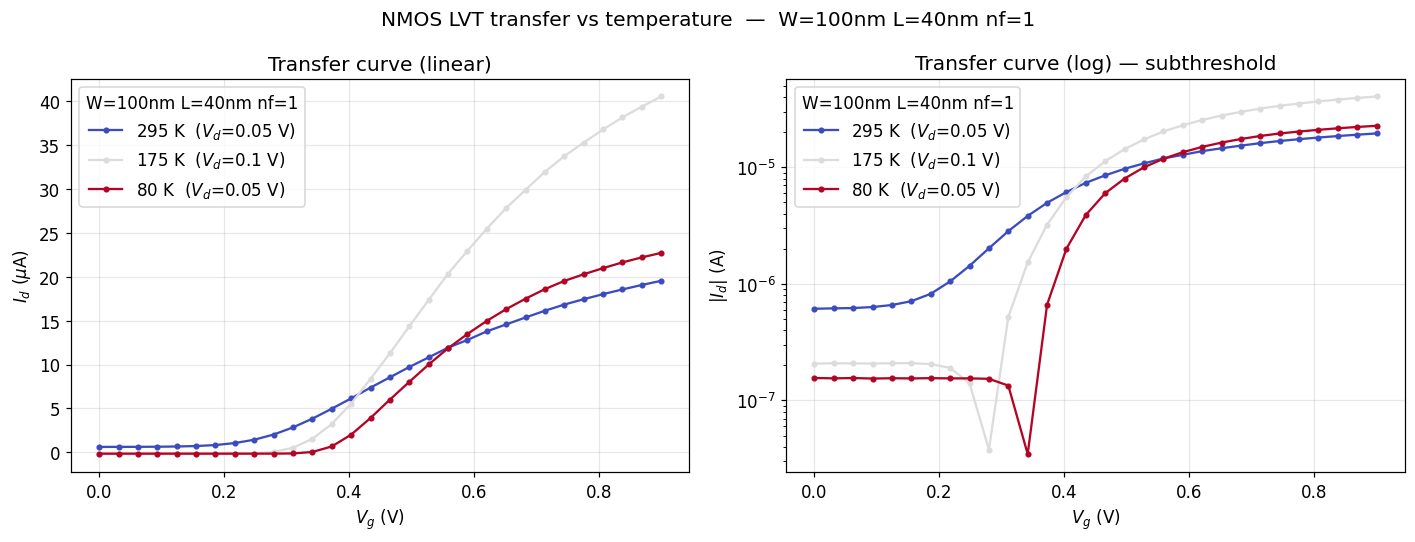

In [ ]:
def device_for_geom(df, W, L, nf):
    """Return one device's rows matching a geometry (first match)."""
    sel = df[np.isclose(df['w'], W) & np.isclose(df['l'], L) & (df['nf'] == nf)]
    if not len(sel):
        return None
    r, c = sel.iloc[0][['Row_idx', 'Col_idx']]
    return sel[(sel['Row_idx'] == r) & (sel['Col_idx'] == c)]

def subthreshold_slice(T, W, L, nf):
    """Return (sorted Id-Vg rows, vd_used) for the subthreshold plot.
    Prefers the dedicated Vd=0.05 V fast sweep; falls back to the lowest
    non-zero Vd of the transfer grid (0.1 V)."""
    if T in fast_data:
        dev = device_for_geom(fast_data[T], W, L, nf)
        if dev is not None and len(dev):
            return dev.sort_values('vg'), float(dev['vd'].iloc[0])
    dev = device_for_geom(data[T], W, L, nf)
    if dev is None:
        return None, None
    vds = np.sort(data[T]['vd'].unique())
    vd_lin = vds[vds > 1e-6][0]
    return dev[np.isclose(dev['vd'], vd_lin, atol=1e-3)].sort_values('vg'), float(vd_lin)

if focus_geoms:
    gW, gL, gnf = focus_geoms[min(1, len(focus_geoms) - 1)]  # a short-channel example
    colors = plt.cm.coolwarm(np.linspace(0, 1, len(TEMPS)))
    fig, (ax_lin, ax_log) = plt.subplots(1, 2, figsize=(13, 5))
    for T, col in zip(TEMPS, colors):
        s, vd_used = subthreshold_slice(T, gW, gL, gnf)
        if s is None or not len(s):
            continue
        lbl = f'{T} K  ($V_d$={vd_used:g} V)'
        ax_lin.plot(s['vg'], s['id_corr'] * 1e6, '-o', ms=3, color=col, label=lbl)
        ax_log.semilogy(s['vg'], np.abs(s['id_corr']) + 1e-14, '-o', ms=3, color=col, label=lbl)
    for ax in (ax_lin, ax_log):
        ax.set_xlabel('$V_g$ (V)')
        ax.legend(title=f'{fmt_geom(gW, gL, gnf)}')
    ax_lin.set_ylabel('$I_d$ ($\\mu$A)')
    ax_lin.set_title('Transfer curve (linear, leakage-subtracted)')
    ax_log.set_ylabel('$|I_d|$ (A)')
    ax_log.set_title('Transfer curve (log, leakage-subtracted) — subthreshold')
    fig.suptitle(f'NMOS LVT transfer vs temperature  —  {fmt_geom(gW, gL, gnf)}')
    fig.tight_layout()
    plt.show()
else:
    print('No common geometry available yet.')

## 4b. Background (leakage) subtraction: before vs after

Each measured $I_d$ includes a $V_d$-dependent leakage flowing through the *inactive* array devices. We estimate it per device and per $V_d$ as $I_d(V_g = 0)$ (channel off) and subtract it: $I_d^{corr} = I_d - I_d(V_g{=}0)$. Below, for one short-channel example device at the warmest temperature (largest leakage), the full family of $V_g$ sweeps is shown raw (left) vs leakage-subtracted (right), followed by the subthreshold log plot showing how removing the background reveals the true turn-on and shifts the extracted $V_{th}$.

In [ ]:
# Example device: shortest-channel device at the warmest temperature, where the
# Vd-dependent leakage background is largest and most visible.
ex_T = max(TEMPS)
ex_L = min(L for (_, L, _) in focus_geoms) if focus_geoms else None
ex_W, ex_nf = W_SEL, NF_SEL
ex_dev = device_for_geom(data[ex_T], ex_W, ex_L, ex_nf) if ex_L is not None else None

if ex_dev is not None and len(ex_dev):
    vd_vals = np.sort(ex_dev['vd'].unique())
    cmap = plt.cm.viridis(np.linspace(0, 0.9, len(vd_vals)))

    # Figure 1: full Vg-sweep family, raw (left) vs leakage-subtracted (right)
    fig, (axr, axc) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
    for vd, col in zip(vd_vals, cmap):
        s = ex_dev[np.isclose(ex_dev['vd'], vd, atol=1e-3)].sort_values('vg')
        axr.plot(s['vg'], s['id'] * 1e6, '-', color=col, label=f'{vd:.1f}')
        axc.plot(s['vg'], s['id_corr'] * 1e6, '-', color=col, label=f'{vd:.1f}')
    axr.set_title('Raw $I_d$ (includes array leakage)')
    axc.set_title('Leakage-subtracted $I_d$  ($I_d - I_d(V_g{=}0)$ per $V_d$)')
    for ax in (axr, axc):
        ax.set_xlabel('$V_g$ (V)')
        ax.axhline(0, color='k', lw=0.6)
    axr.set_ylabel('$I_d$ ($\\mu$A)')
    axc.legend(title='$V_d$ (V)', fontsize=8, ncol=2)
    fig.suptitle(f'NMOS LVT  {fmt_geom(ex_W, ex_L, ex_nf)} @ {ex_T} K  -  full $V_g$ sweep family')
    fig.tight_layout()
    plt.show()

    # Figure 2: subthreshold (log) at the linear Vd slice, before vs after
    vd_lin = vd_vals[vd_vals > 1e-6][0]
    s = ex_dev[np.isclose(ex_dev['vd'], vd_lin, atol=1e-3)].sort_values('vg')
    i0_row = s[np.isclose(s['vg'], 0.0, atol=1e-3)]
    i0 = float(i0_row['id'].iloc[0]) if len(i0_row) else np.nan
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.semilogy(s['vg'], np.abs(s['id']) + 1e-14, '-o', ms=3, color='0.6', label='raw')
    ax.semilogy(s['vg'], np.abs(s['id_corr']) + 1e-14, '-o', ms=3, color='C3',
                label='leakage-subtracted')
    if np.isfinite(i0):
        ax.axhline(abs(i0), color='0.6', ls='--', lw=1,
                   label=f'baseline $I_d(V_g{{=}}0)$ = {i0*1e6:.2f} $\\mu$A')
    ax.set_xlabel('$V_g$ (V)')
    ax.set_ylabel('$|I_d|$ (A)')
    ax.set_title(f'Subthreshold at $V_d$={vd_lin:.1f} V  -  background removal reveals turn-on')
    ax.legend(fontsize=9)
    fig.tight_layout()
    plt.show()

    # Impact on extracted Vth for this device
    def _vth_from(vg, idd):
        gm = np.gradient(idd, vg)
        k = int(np.nanargmax(gm))
        return vg[k] - idd[k] / gm[k] - vd_lin / 2.0 if gm[k] > 0 else np.nan
    vg = s['vg'].to_numpy(float)
    print(f'Example device {fmt_geom(ex_W, ex_L, ex_nf)} @ {ex_T} K:')
    print(f'  Vth raw                = {_vth_from(vg, s["id"].to_numpy(float)):.3f} V')
    print(f'  Vth leakage-subtracted = {_vth_from(vg, s["id_corr"].to_numpy(float)):.3f} V')
else:
    print('Example geometry not available.')

## 5. Threshold voltage vs temperature

$V_{th}$ for each length in the focus series. NMOS $V_{th}$ typically **increases** as
temperature drops (carrier freeze-out / reduced thermal generation).

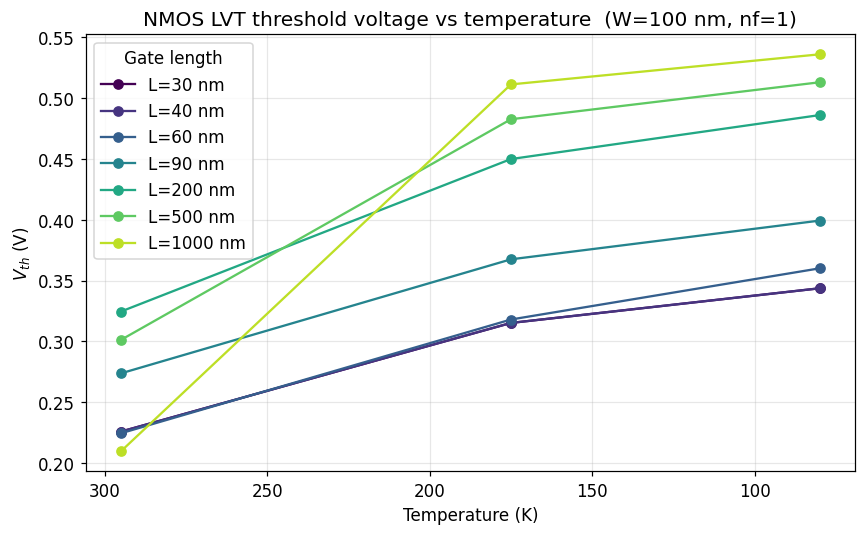

In [30]:
def metric_vs_T(metric_col, W, L, nf):
    xs, ys = [], []
    for T in TEMPS:
        m = metrics[T]
        sel = m[np.isclose(m['W'], W) & np.isclose(m['L'], L) & (m['nf'] == nf)]
        if len(sel):
            xs.append(T)
            ys.append(np.nanmedian(sel[metric_col]))  # robust over nominally identical dies
    return xs, ys

if focus_geoms:
    fig, ax = plt.subplots()
    cmap = plt.cm.viridis(np.linspace(0, 0.9, len(focus_geoms)))
    for (W, L, nf), col in zip(focus_geoms, cmap):
        xs, ys = metric_vs_T('Vth', W, L, nf)
        ax.plot(xs, ys, '-o', color=col, label=f'L={L*1e9:.0f} nm')
    ax.set_xlabel('Temperature (K)')
    ax.set_ylabel('$V_{th}$ (V)')
    ax.set_title(f'NMOS LVT threshold voltage vs temperature  (W={W_SEL*1e9:.0f} nm, nf={NF_SEL})')
    ax.legend(title='Gate length')
    ax.invert_xaxis()
    fig.tight_layout()
    plt.show()

## 6. Saturation current vs temperature

On-state drive current $I_{sat}$ (at $V_g = V_d = 0.9\,$V), normalized per unit width.
Cryogenic operation usually **boosts** drive current via higher mobility.

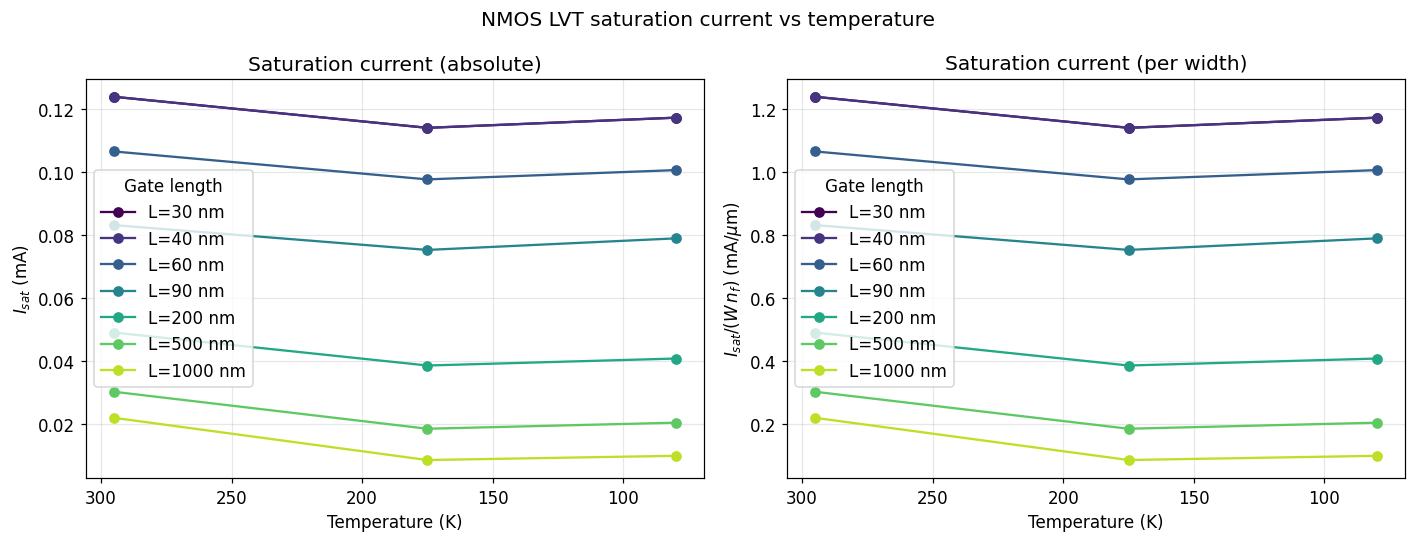

In [31]:
if focus_geoms:
    fig, (ax_abs, ax_norm) = plt.subplots(1, 2, figsize=(13, 5))
    cmap = plt.cm.viridis(np.linspace(0, 0.9, len(focus_geoms)))
    for (W, L, nf), col in zip(focus_geoms, cmap):
        xs, ys = metric_vs_T('Isat', W, L, nf)
        ax_abs.plot(xs, [y * 1e3 for y in ys], '-o', color=col, label=f'L={L*1e9:.0f} nm')
        xs, yn = metric_vs_T('Isat_per_W', W, L, nf)
        ax_norm.plot(xs, [y * 1e-3 for y in yn], '-o', color=col, label=f'L={L*1e9:.0f} nm')
    for ax in (ax_abs, ax_norm):
        ax.set_xlabel('Temperature (K)')
        ax.legend(title='Gate length')
        ax.invert_xaxis()
    ax_abs.set_ylabel('$I_{sat}$ (mA)')
    ax_abs.set_title('Saturation current (absolute)')
    ax_norm.set_ylabel('$I_{sat} / (W\\,n_f)$ (mA/$\\mu$m)')
    ax_norm.set_title('Saturation current (per width)')
    fig.suptitle('NMOS LVT saturation current vs temperature')
    fig.tight_layout()
    plt.show()

## 7. Length scaling of $V_{th}$ at each temperature

$V_{th}$ vs gate length $L$ — short-channel roll-off, and how it sharpens at cryo.

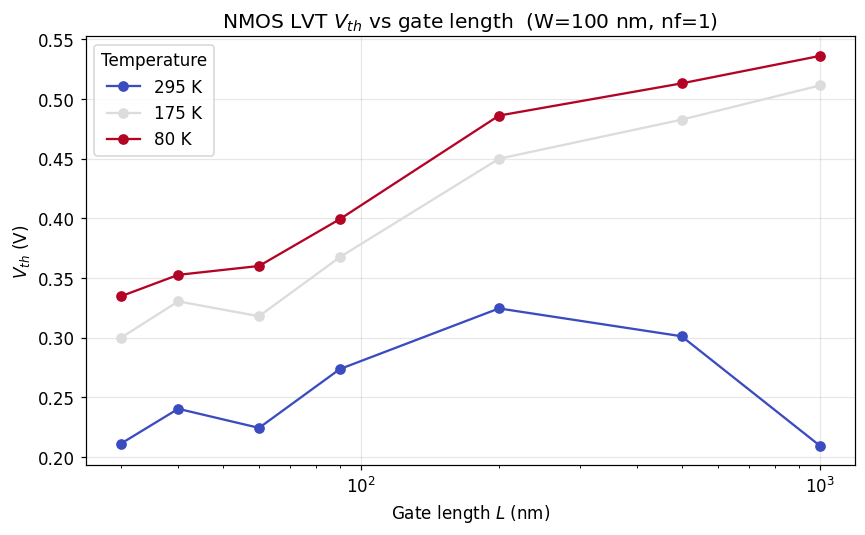

In [32]:
fig, ax = plt.subplots()
colors = plt.cm.coolwarm(np.linspace(0, 1, len(TEMPS)))
for T, col in zip(TEMPS, colors):
    m = metrics[T]
    sel = m[np.isclose(m['W'], W_SEL) & (m['nf'] == NF_SEL)].copy()
    g = sel.groupby('L')['Vth'].mean().sort_index()
    ax.plot(g.index * 1e9, g.values, '-o', color=col, label=f'{T} K')
ax.set_xscale('log')
ax.set_xlabel('Gate length $L$ (nm)')
ax.set_ylabel('$V_{th}$ (V)')
ax.set_title(f'NMOS LVT $V_{{th}}$ vs gate length  (W={W_SEL*1e9:.0f} nm, nf={NF_SEL})')
ax.legend(title='Temperature')
fig.tight_layout()
plt.show()

## 8. Summary table

Median metrics per temperature across the full array.

In [33]:
summary = pd.DataFrame({
    'Temperature (K)': TEMPS,
    'N devices': [len(metrics[T]) for T in TEMPS],
    'Vth median (V)': [round(metrics[T]['Vth'].median(), 3) for T in TEMPS],
    'Vth spread (V)': [round(metrics[T]['Vth'].std(), 3) for T in TEMPS],
    'Isat median (mA)': [round(metrics[T]['Isat'].median() * 1e3, 3) for T in TEMPS],
}).set_index('Temperature (K)')
summary

,N devices,Vth median (V),Vth spread (V),Isat median (mA)
Temperature (K),,,,
295,150,0.311,0.075,0.532
175,150,0.387,0.080,0.577
80,150,0.421,0.080,0.609
